# **Projet DM : Practical Work Project**
----------------------------------------------
## **Step 1: Data Analysis and Preprocessing**
- Exploratory Data Analysis
- Data Preprocessing
- Feature Engineering:
  - Supervised learning
  - Unsupervised learning
### Resources :
- **Dataset ** https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land-monthly-means?tab=download
- **Project detail** https://classroom.google.com/u/5/c/ODkyMjU5MDM2Nzk3/m/ODkyOTIxMDk1MDg5/details


In [2]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
import os
data_path = os.path.join("drive", "MyDrive", "Projet_DataMining", "Data")

Mounted at /content/drive


# **DATA LOADING**
We load our data using xarray since it's a NetCDF4 file

In [46]:
import xarray

rawdata = xarray.open_dataset(os.path.join(data_path, "data.nc"))
print(rawdata.data_vars)

original_points = rawdata.sizes["latitude"] * rawdata.sizes["longitude"]
print("Raw data grid point size : ", original_points)

Data variables:
    d2m      (valid_time, latitude, longitude) float32 21MB ...
    t2m      (valid_time, latitude, longitude) float32 21MB ...
    slhf     (valid_time, latitude, longitude) float32 21MB ...
    ssr      (valid_time, latitude, longitude) float32 21MB ...
    str      (valid_time, latitude, longitude) float32 21MB ...
    sshf     (valid_time, latitude, longitude) float32 21MB ...
    ro       (valid_time, latitude, longitude) float32 21MB ...
    e        (valid_time, latitude, longitude) float32 21MB ...
    u10      (valid_time, latitude, longitude) float32 21MB ...
    v10      (valid_time, latitude, longitude) float32 21MB ...
    sp       (valid_time, latitude, longitude) float32 21MB ...
    tp       (valid_time, latitude, longitude) float32 21MB ...
Raw data grid point size :  37674


### **Reducing spatial resolution**
from tp : Reduce the spatial resolution of the map by a factor of four by aggregating
neighboring grid points

Our data is a 3D block in which xyz correspond to latitute longtitute and time, the inner values of this block can be temperature or radiation ect ect.

### **Getting only algeria :**
We can get the algeria part of the border box, we use the geoJSON for this

In [47]:
import numpy as np
import xarray as xr
import geopandas as gpd
from shapely import contains_xy

# Reduce res of data 2 BY 2
data = rawdata.coarsen(latitude=2, longitude=2, boundary="trim").mean()
reduced_points = data.sizes["latitude"] * data.sizes["longitude"]

print("Grid point size after Resolution Reduction:", reduced_points,
      f"({(1 - reduced_points / original_points) * 100:.2f}% reduction)")


algeria = gpd.read_file(os.path.join(data_path, "dz.json")).to_crs(4326)
algeria_shape = algeria.union_all()
lon2d, lat2d = np.meshgrid(data.longitude.values, data.latitude.values)
mask = xr.DataArray( # only get the area that falls under algeria border
    contains_xy(algeria_shape, lon2d, lat2d),
    coords={"latitude": data.latitude, "longitude": data.longitude},
    dims=["latitude", "longitude"],
)

data = data.where(mask, drop=True)
print("Grid point size after getting only Algerian borders:",int(mask.sum().item()),f"({(1 - mask.sum().item() / reduced_points) * 100:.2f}% reduction)")
print("Total grid point reduction:", f"{(1 - mask.sum().item() / original_points) * 100:.2f}%")

Grid point size after Resolution Reduction: 9373 (75.12% reduction)
Grid point size after getting only Algerian borders: 5316 (43.28% reduction)
Total grid point reduction: 85.89%


### **Missing Values**
We notice around 572037 missing values for all attributes, this is after getting only algeria out of the border box (which included areas like Morroco Tunisia ect). The values of regions outside the border got replaced with NaN values.

In [48]:
import pandas as pd
import numpy

# convert data to pandas
dataframe = data.to_dataframe().reset_index()

# missing values check
print("shape before:", dataframe.shape)
print(dataframe.isna().sum())
print("rows with at least one NaN:", dataframe.isna().any(axis=1).sum(),
      f"({dataframe.isna().any(axis=1).mean()})")

shape before: (1321593, 17)
valid_time         0
latitude           0
longitude          0
d2m           572037
t2m           572037
slhf          572037
ssr           572037
str           572037
sshf          572037
ro            572037
e             572037
u10           572037
v10           572037
sp            572037
tp            572037
number             0
expver             0
dtype: int64
rows with at least one NaN: 572037 (0.43283900565453964)


In [49]:
from shapely import contains_xy

coarse = rawdata.coarsen(latitude=2, longitude=2, boundary="trim").mean()
lon2d, lat2d = np.meshgrid(coarse.longitude.values, coarse.latitude.values)
t0 = coarse["t2m"].isel(valid_time=0).isnull().values

for name, shape in [("Border points total :", algeria_shape),
                    ("border + 0.2° offset", algeria_shape.buffer(0.2))]:
    inside = contains_xy(shape, lon2d, lat2d)
    missing = inside & t0
    print(f"{name}: {inside.sum()} points included - {missing.sum()} are missing")

Border points total :: 5316 points included - 0 are missing
border + 0.2° offset: 5651 points included - 41 are missing


In [50]:
# removal of missing values
dataframe = dataframe.dropna().reset_index(drop=True)
og_dataframe = dataframe.copy()

print("shape after:", dataframe.shape)
print("period", dataframe.valid_time.min(), "until", dataframe.valid_time.max())
print("duplicates:", dataframe.duplicated(["latitude", "longitude", "valid_time"]).sum())

dataframe.head()

shape after: (749556, 17)
period 2015-01-01 00:00:00 until 2026-09-01 00:00:00
duplicates: 0


,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp,number,expver
0,2015-01-01,37.05,6.45,279.326263,283.089752,-4914878.5,8015607.5,-4886053.5,771872.0,0.000429,-0.001965,2.933837,-0.261126,98269.210938,0.005319,0,0001
1,2015-01-01,37.05,7.25,281.102295,285.274658,-6915168.0,8132020.0,-5270822.0,3630702.0,0.000218,-0.002765,3.638752,-0.917213,101482.875000,0.006041,0,0001
2,2015-01-01,36.85,3.85,279.121826,283.517822,-4578554.0,7500012.5,-5199213.5,1702137.0,0.000378,-0.001831,2.284870,0.571068,99910.875000,0.005009,0,0001
3,2015-01-01,36.85,4.05,278.532959,282.673584,-4206622.5,7533636.5,-4928927.0,1089806.5,0.000711,-0.001682,2.284626,0.510155,98286.125000,0.005580,0,0001
4,2015-01-01,36.85,4.25,278.505280,282.477142,-4142702.0,7510356.5,-4913180.5,1040296.0,0.000784,-0.001657,2.298257,0.530866,98183.875000,0.005938,0,0001


### **preparing the data**
data only has time as yyyy-mm-dd so best to seperate months and year with this

Units conversion has to be done to more general units so that the values are legible...
| variable | raw unit | new unit | operation |
|---|---|---|---|
| t2m, d2m | K | °C | − 273.15 |
| slhf, ssr, str, sshf | J/m² per day | W/m² | ÷ 86400 |
| tp, ro | m per day | mm/day | × 1000 |
| e | m per day (negative) | mm/day (positive) | × −1000 |
| sp | Pa | hPa | ÷ 100 |

In [51]:
dataframe["month"] = og_dataframe["valid_time"].dt.month
dataframe["year"] = og_dataframe["valid_time"].dt.year


dataframe = pd.DataFrame({
    "valid_time": dataframe["valid_time"],
    "latitude": dataframe["latitude"],
    "longitude": dataframe["longitude"],
    "year": dataframe["valid_time"].dt.year,
    "month": dataframe["valid_time"].dt.month,
    "temperature_2m": dataframe["t2m"] - 273.15,
    "dewpoint_temperature_2m": dataframe["d2m"] - 273.15,
    "surface_latent_heat_flux": dataframe["slhf"] / 86400,
    "surface_net_solar_radiation": dataframe["ssr"] / 86400,
    "surface_net_thermal_radiation": dataframe["str"] / 86400,
    "surface_sensible_heat_flux": dataframe["sshf"] / 86400,
    "runoff": dataframe["ro"] * 1000,
    "total_evaporation": dataframe["e"] * 1000,
    "wind_u_10m": dataframe["u10"],
    "wind_v_10m": dataframe["v10"],
    "surface_pressure": dataframe["sp"] / 100,
    "total_precipitation": dataframe["tp"] * 1000,
})
dataframe.head()


,valid_time,latitude,longitude,year,month,temperature_2m,dewpoint_temperature_2m,surface_latent_heat_flux,surface_net_solar_radiation,surface_net_thermal_radiation,surface_sensible_heat_flux,runoff,total_evaporation,wind_u_10m,wind_v_10m,surface_pressure,total_precipitation
0,2015-01-01,37.05,6.45,2015,1,9.939758,6.176270,-56.885166,92.773232,-56.551544,8.933703,0.429064,-1.965323,2.933837,-0.261126,982.692139,5.318568
1,2015-01-01,37.05,7.25,2015,1,12.124664,7.952301,-80.036667,94.120605,-61.004883,42.022015,0.218026,-2.765182,3.638752,-0.917213,1014.828735,6.041232
2,2015-01-01,36.85,3.85,2015,1,10.367828,5.971832,-52.992523,86.805702,-60.176083,19.700659,0.377582,-1.830836,2.284870,0.571068,999.108765,5.009431
3,2015-01-01,36.85,4.05,2015,1,9.523590,5.382965,-48.687759,87.194870,-57.047768,12.613502,0.711489,-1.682110,2.284626,0.510155,982.861267,5.579656
4,2015-01-01,36.85,4.25,2015,1,9.327148,5.355286,-47.947941,86.925423,-56.865517,12.040462,0.784129,-1.656551,2.298257,0.530866,981.838745,5.938498


# **UNIVARIATE EXPLORATORY DATA ANALSYS**

In [52]:
eda_features = [
    "temperature_2m",
    "dewpoint_temperature_2m",
    "surface_latent_heat_flux",
    "surface_net_solar_radiation",
    "surface_net_thermal_radiation",
    "surface_sensible_heat_flux",
    "runoff",
    "total_evaporation",
    "wind_u_10m",
    "wind_v_10m",
    "surface_pressure",
    "total_precipitation",
]

### **Distribution : Centrality (mode median mean)**
- Symmetrical Mean = Median = Mode Bell-shaped
- Positively Skewed (Right-skewed) Mean > Median > Mode Tail on the right
- Negatively Skewed (Left-skewed) Mode > Median > Mean Tail on the left

In [53]:
centrality = pd.DataFrame({
    "mean":   dataframe[eda_features].mean(),
    "median": dataframe[eda_features].median(),
    "mode":   dataframe[eda_features].mode().iloc[0],
})
display(centrality)

,mean,median,mode
temperature_2m,23.891640,24.226837,33.726227
dewpoint_temperature_2m,1.517377,1.310944,0.919586
surface_latent_heat_flux,-5.676898,-2.105859,-2.196713
surface_net_solar_radiation,156.235611,161.561356,184.765366
surface_net_thermal_radiation,-110.128090,-114.831711,-143.955734
surface_sensible_heat_flux,-39.210846,-39.465332,-46.222366
runoff,0.003198,0.000056,0.000000
total_evaporation,-0.196124,-0.072755,-0.022453
wind_u_10m,-1.030365,-0.999835,-1.073835
wind_v_10m,-0.514312,-0.466970,-0.520952


### **Distribution : Dispersion (varience, ecart type, range, iqr)**

In [54]:
dispersion = pd.DataFrame({
    "variance": dataframe[eda_features].var(),
    "std":      dataframe[eda_features].std(),
    "range":    dataframe[eda_features].max() - dataframe[eda_features].min(), # distance of largest and smallest val
    "midrange": (dataframe[eda_features].max() + dataframe[eda_features].min()) / 2, # avg of largest and smallest val
    "Q1":       dataframe[eda_features].quantile(0.25), # (25% of the data are below Q1).
    "Q3":       dataframe[eda_features].quantile(0.50), # 75% of the data are below Q3).
    "IQR":      dataframe[eda_features].quantile(0.75) - dataframe[eda_features].quantile(0.25), # Q3 - Q1
})
display(dispersion)

,variance,std,range,midrange,Q1,Q3,IQR
temperature_2m,76.679810,8.756701,40.244385,21.036407,16.397125,24.226837,15.345215
dewpoint_temperature_2m,22.976038,4.793333,40.742172,2.763344,-1.737885,1.310944,6.291016
surface_latent_heat_flux,125.701668,11.211676,153.149429,-76.620659,-3.627496,-2.105859,2.627565
surface_net_solar_radiation,2403.895020,49.029533,280.115051,171.970215,117.238718,161.561356,77.443048
surface_net_thermal_radiation,907.008911,30.116589,147.769791,-98.751808,-134.129009,-114.831707,41.909651
surface_sensible_heat_flux,494.762848,22.243265,242.195587,-59.902752,-53.782138,-39.465330,32.509235
runoff,0.000842,0.029012,3.716235,1.858118,0.000006,0.000056,0.000346
total_evaporation,0.149998,0.387295,5.291151,-2.647163,-0.125326,-0.072755,0.090779
wind_u_10m,2.511581,1.584797,14.179141,0.380843,-2.135951,-0.999835,2.190324
wind_v_10m,1.087453,1.042810,8.096371,-0.761301,-1.158880,-0.466970,1.352631


### **OUTLIERS**

Outliers are data values too different from other stuff, methods for detecting them are zscore, IQR, Boxplot, Scatter plot

In [55]:
# z score method
z_scores = (dataframe[eda_features] - dataframe[eda_features].mean()) / dataframe[eda_features].std()
z_outliers = (z_scores > 3) | (z_scores < -3)

# IQR method
Q1 = dataframe[eda_features].quantile(0.25)
Q3 = dataframe[eda_features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = (dataframe[eda_features] < lower_bound) | (dataframe[eda_features] > upper_bound)

outliers = pd.DataFrame({
    "zscore": z_outliers.sum(),
    "IQR": iqr_outliers.sum()
})
display(outliers)

,zscore,IQR
temperature_2m,0,0
dewpoint_temperature_2m,3449,7997
surface_latent_heat_flux,20910,123039
surface_net_solar_radiation,2,1
surface_net_thermal_radiation,0,322
surface_sensible_heat_flux,4459,5382
runoff,5780,121232
total_evaporation,20917,123039
wind_u_10m,3034,5354
wind_v_10m,1675,8154


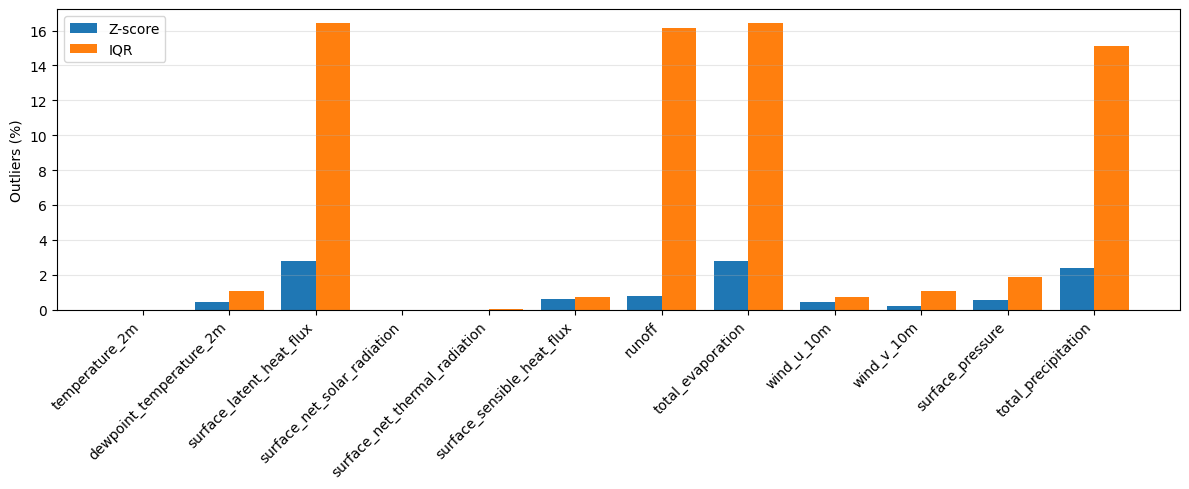

In [56]:
import matplotlib.pyplot as plt
import numpy as np

outlier_percentages = (outliers / len(dataframe) * 100).round(2)

x = np.arange(len(outlier_percentages)); width = 0.35

plt.figure(figsize=(12,5))
x = np.arange(len(outliers))
plt.bar(x-0.2, outliers["zscore"]/len(dataframe)*100, 0.4, label="Z-score")
plt.bar(x+0.2, outliers["IQR"]/len(dataframe)*100, 0.4, label="IQR")
plt.xticks(x, outliers.index, rotation=45, ha="right")
plt.ylabel("Outliers (%)"); plt.legend(); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

### **BOX PLOT**

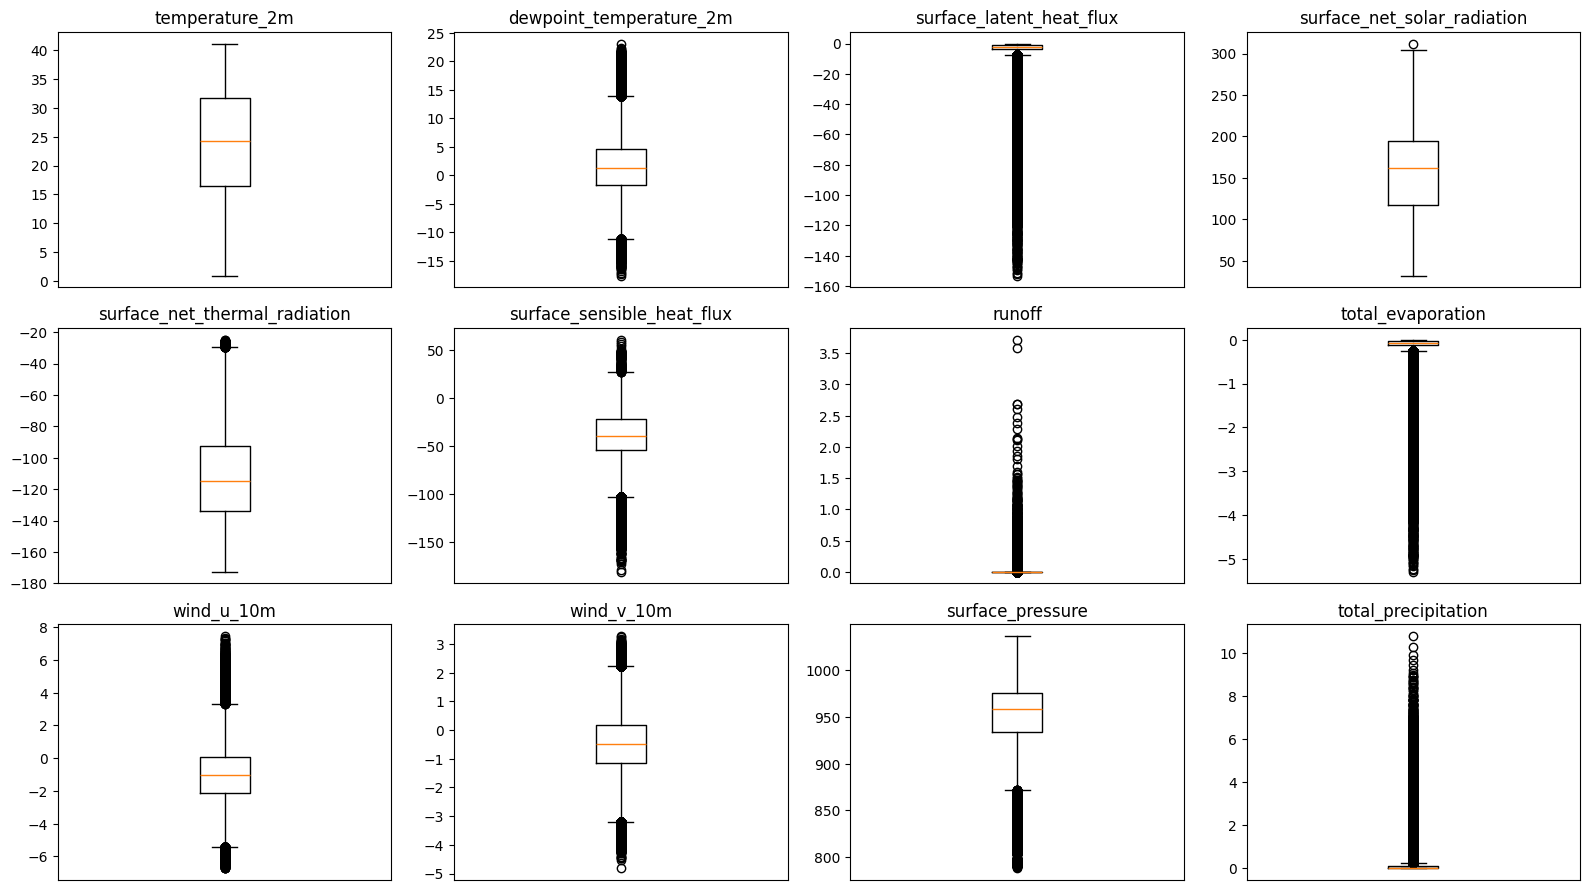

In [57]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), eda_features):
    ax.boxplot(dataframe[c].dropna())
    ax.set_title(c)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

### **SCATTER PLOT :**
checks corellation of two values (how closely related they are)
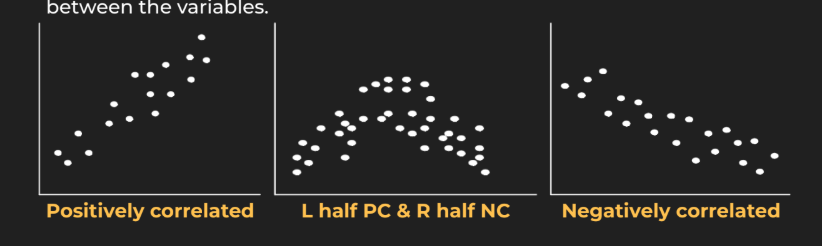

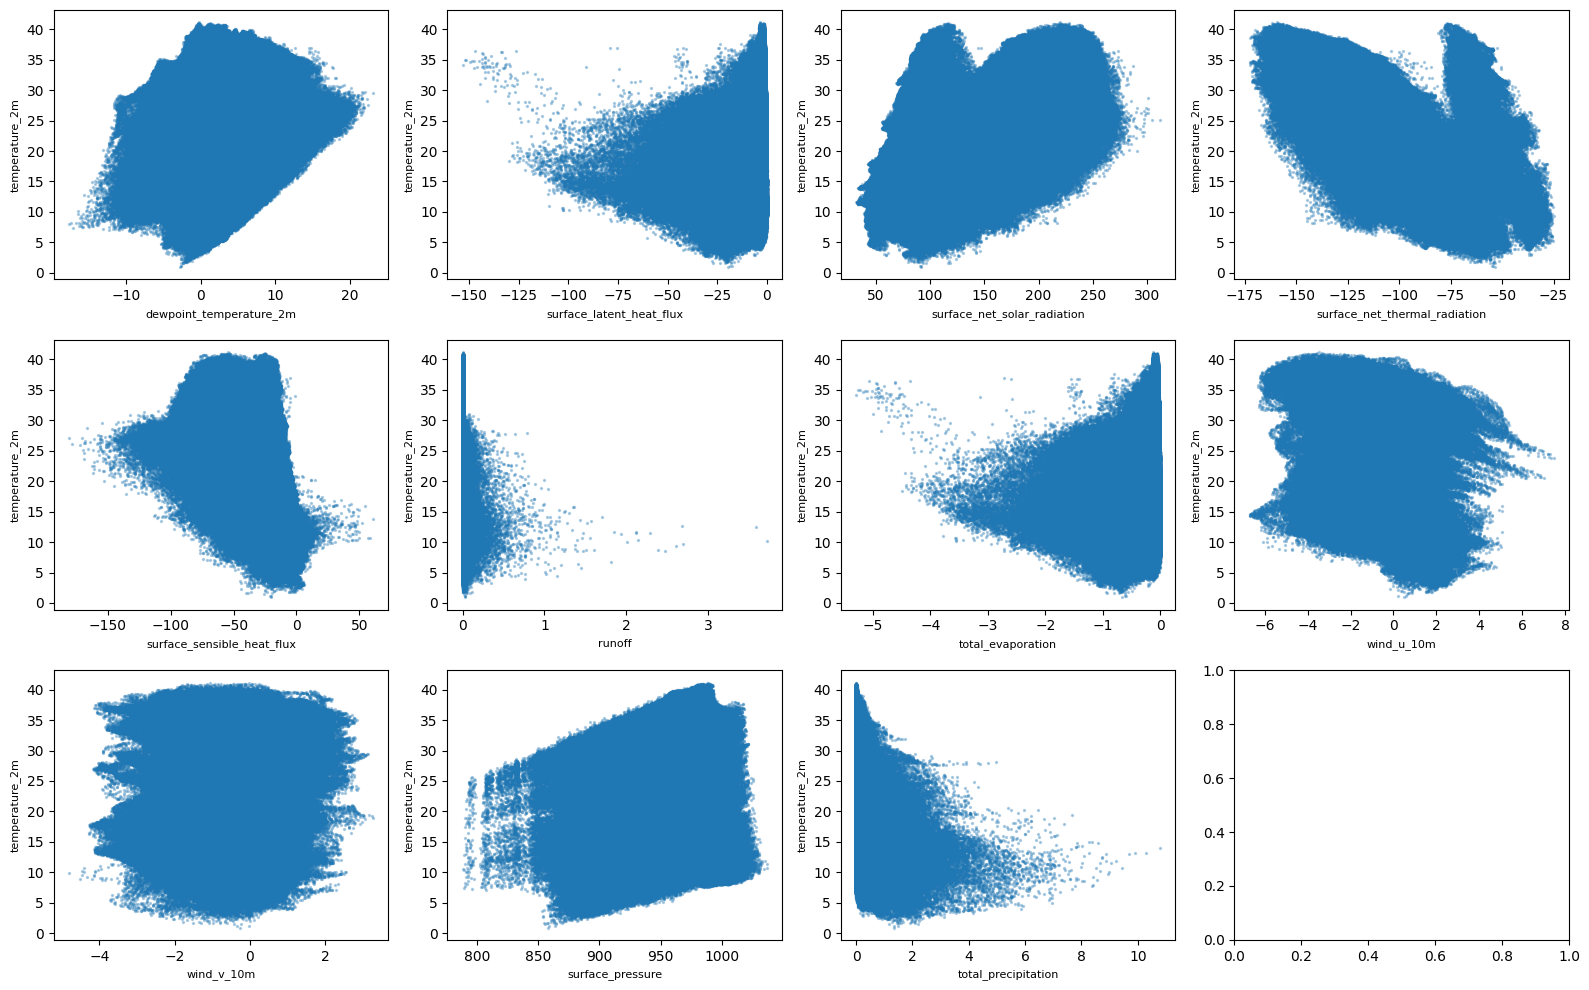

In [58]:
import matplotlib.pyplot as plt

others = [c for c in eda_features if c != "temperature_2m"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), others):
    ax.scatter(dataframe[c], dataframe["temperature_2m"], s=2, alpha=0.3)
    ax.set_xlabel(c, fontsize=8)
    ax.set_ylabel("temperature_2m", fontsize=8)
plt.tight_layout()
plt.show()

### **Quantille PLot**


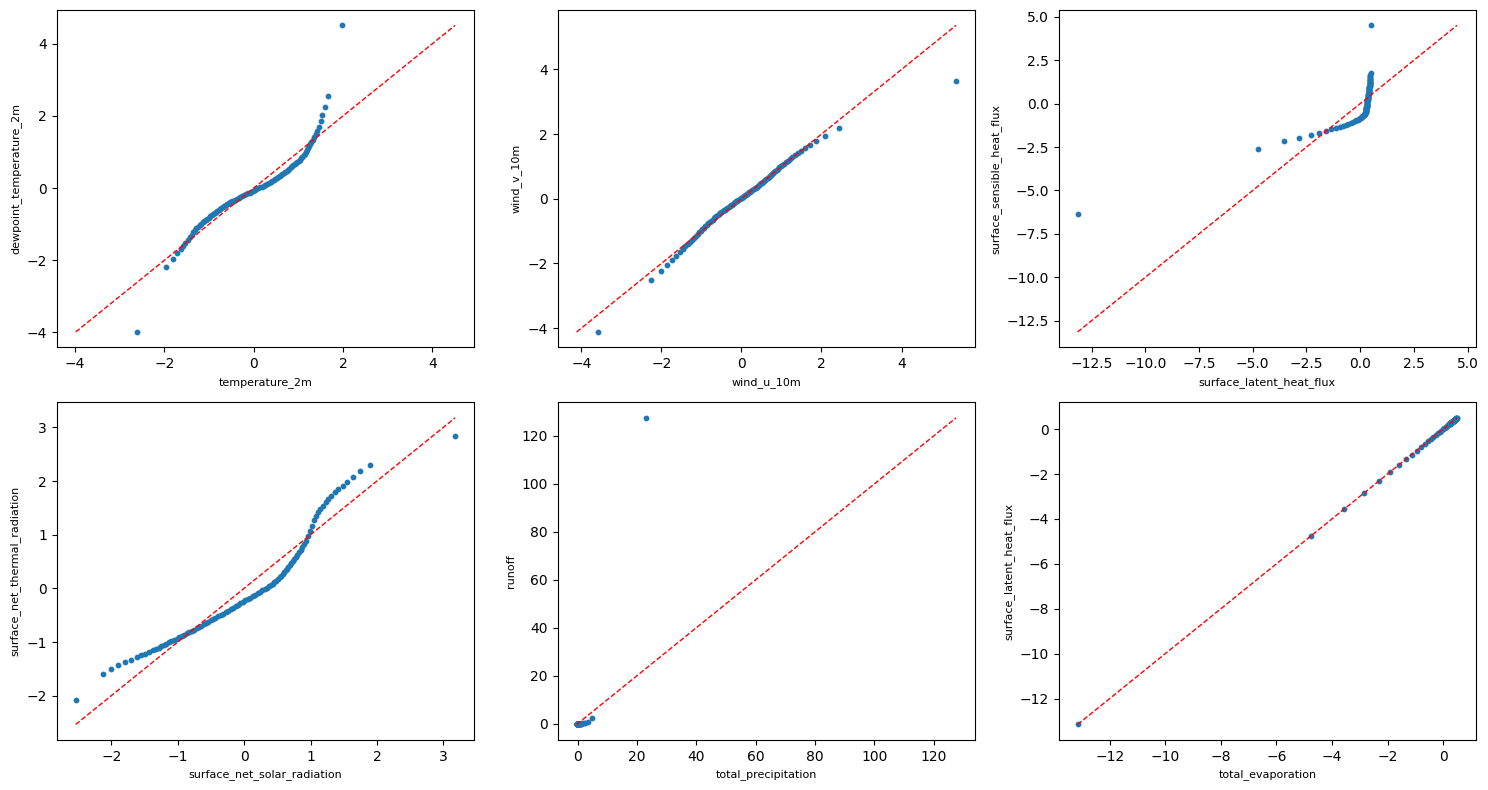

In [59]:
import numpy as np
import matplotlib.pyplot as plt

def qq_pair(ax, x, y, x_name, y_name, standardize=False):
    x = x.dropna().to_numpy()
    y = y.dropna().to_numpy()
    if standardize:
        x = (x - x.mean()) / x.std()
        y = (y - y.mean()) / y.std()
    q = np.linspace(0, 1, 100)
    qx, qy = np.quantile(x, q), np.quantile(y, q)
    ax.scatter(qx, qy, s=10)
    lims = [min(qx.min(), qy.min()), max(qx.max(), qy.max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_xlabel(x_name, fontsize=8)
    ax.set_ylabel(y_name, fontsize=8)


pairs = [
    ("temperature_2m", "dewpoint_temperature_2m"),
    ("wind_u_10m", "wind_v_10m"),
    ("surface_latent_heat_flux", "surface_sensible_heat_flux"),
    ("surface_net_solar_radiation", "surface_net_thermal_radiation"),
    ("total_precipitation", "runoff"),
    ("total_evaporation", "surface_latent_heat_flux"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (a, b) in zip(axes.ravel(), pairs):
    qq_pair(ax, dataframe[a], dataframe[b], a, b, standardize=True)

plt.tight_layout()
plt.show()

## **Histograms**
We notice four features that are skewed to the sides ‼
- Runoff, Total percipitation, Latent Heat Flux, Total Evaporation

This matches the earlier outlier count in which 15-16% of these feeatures were outliers from the IQR calculations. Most of these values are close to zero due to the vast dry desert of the country, thus instead of deleting them we'll need to resolve them in other ways.

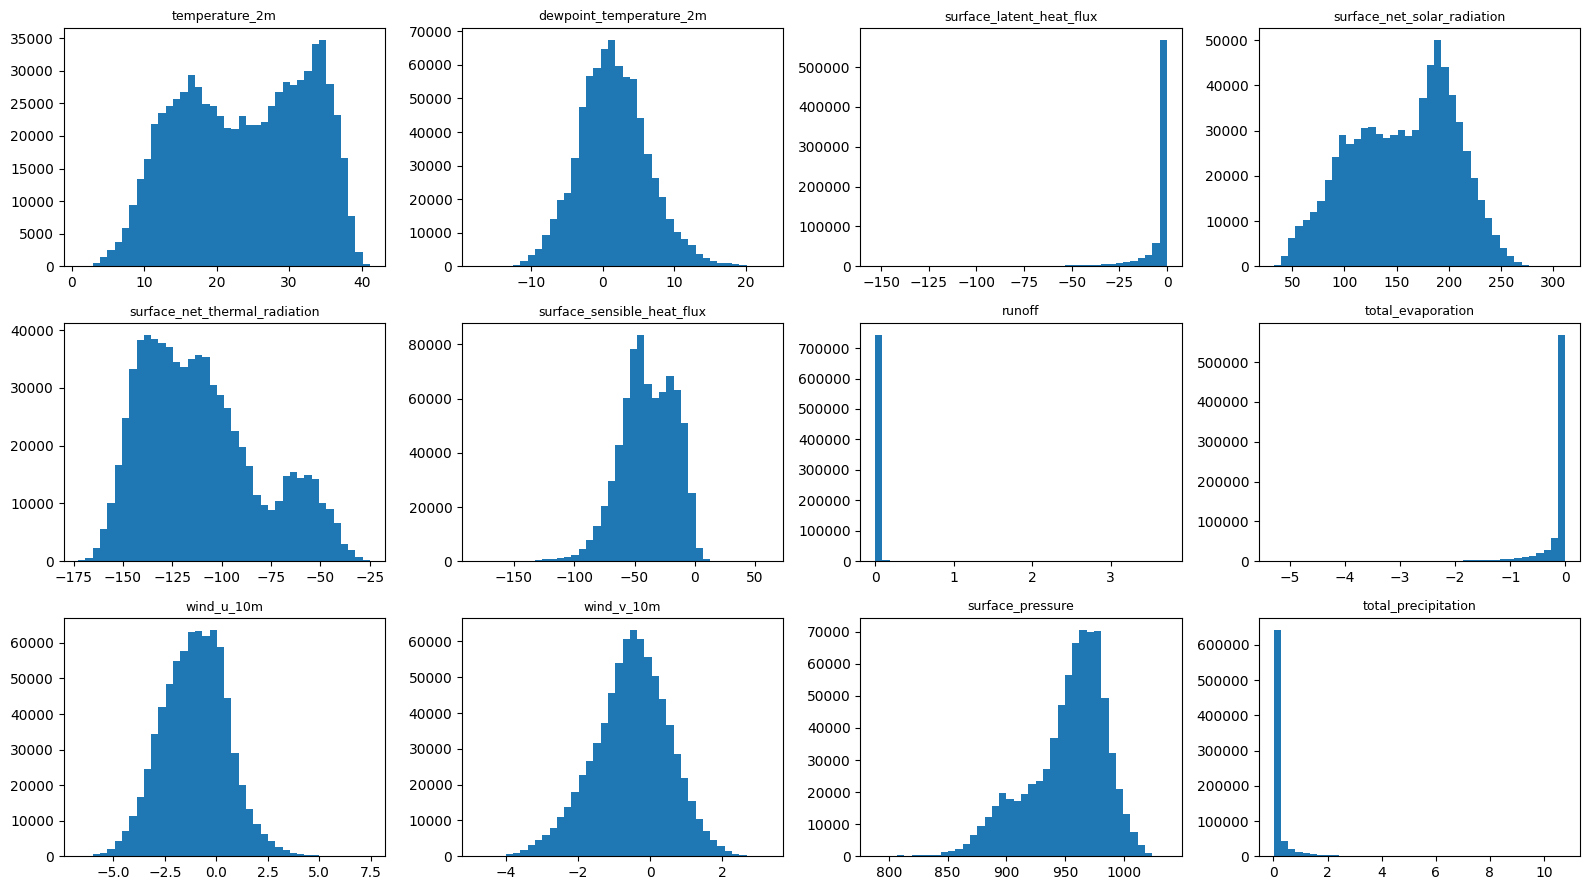

In [60]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), eda_features):
    ax.hist(dataframe[c].dropna(), bins=40)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

### **CORRELATION**
Checks how closely related two features are, 1 means perfect correlation 0 means no correlation (has nothing to do with it)
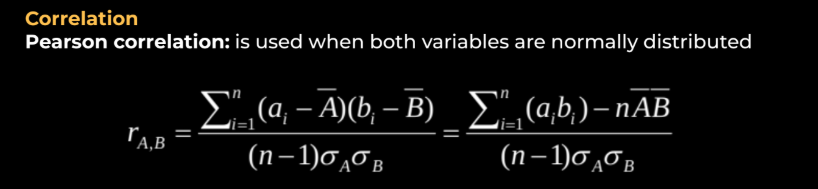

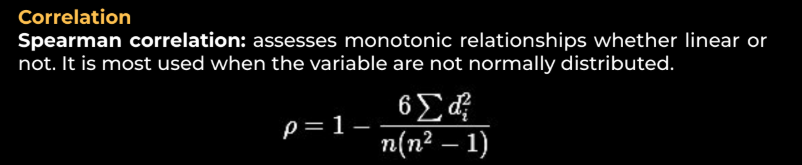

In [61]:
pearson = dataframe[eda_features].corr(method="pearson")
spearman = dataframe[eda_features].corr(method="spearman")
display(pearson.round(1))

,temperature_2m,dewpoint_temperature_2m,surface_latent_heat_flux,surface_net_solar_radiation,surface_net_thermal_radiation,surface_sensible_heat_flux,runoff,total_evaporation,wind_u_10m,wind_v_10m,surface_pressure,total_precipitation
temperature_2m,1.0,0.3,0.2,0.6,-0.6,-0.6,-0.1,0.2,-0.3,0.1,0.1,-0.3
dewpoint_temperature_2m,0.3,1.0,-0.4,0.1,0.1,-0.2,0.1,-0.4,0.0,0.2,0.2,0.3
surface_latent_heat_flux,0.2,-0.4,1.0,-0.1,-0.2,0.1,-0.4,1.0,-0.3,-0.1,0.2,-0.8
surface_net_solar_radiation,0.6,0.1,-0.1,1.0,-0.9,-0.9,0.0,-0.1,-0.0,0.1,-0.2,-0.1
surface_net_thermal_radiation,-0.6,0.1,-0.2,-0.9,1.0,0.7,0.1,-0.2,0.2,-0.1,0.1,0.3
surface_sensible_heat_flux,-0.6,-0.2,0.1,-0.9,0.7,1.0,0.0,0.1,-0.0,-0.2,0.3,0.1
runoff,-0.1,0.1,-0.4,0.0,0.1,0.0,1.0,-0.4,0.1,0.1,-0.0,0.5
total_evaporation,0.2,-0.4,1.0,-0.1,-0.2,0.1,-0.4,1.0,-0.3,-0.1,0.2,-0.8
wind_u_10m,-0.3,0.0,-0.3,-0.0,0.2,-0.0,0.1,-0.3,1.0,0.2,-0.2,0.3
wind_v_10m,0.1,0.2,-0.1,0.1,-0.1,-0.2,0.1,-0.1,0.2,1.0,-0.2,0.1


## **CORRELATION MATRIX**

We notice interesting correlation in particular features like :
- surface_latent_heat_flux and total_evaporation have correlation of 1, which means they share the same exact meaning. Surface latent heat flux might be redundant (unnecessary), as high correlation means it's a repeat.
- surface_net_solar_radiation and surface_net_thermal_radiation	have correlation of -0.9, means they are the opposite.
- surface_latent_heat_flux and total_precipitation have a correlation of -0.9
- surface_net_thermal_radiation and surface_sensible_heat_flux have a correlation of 0.7

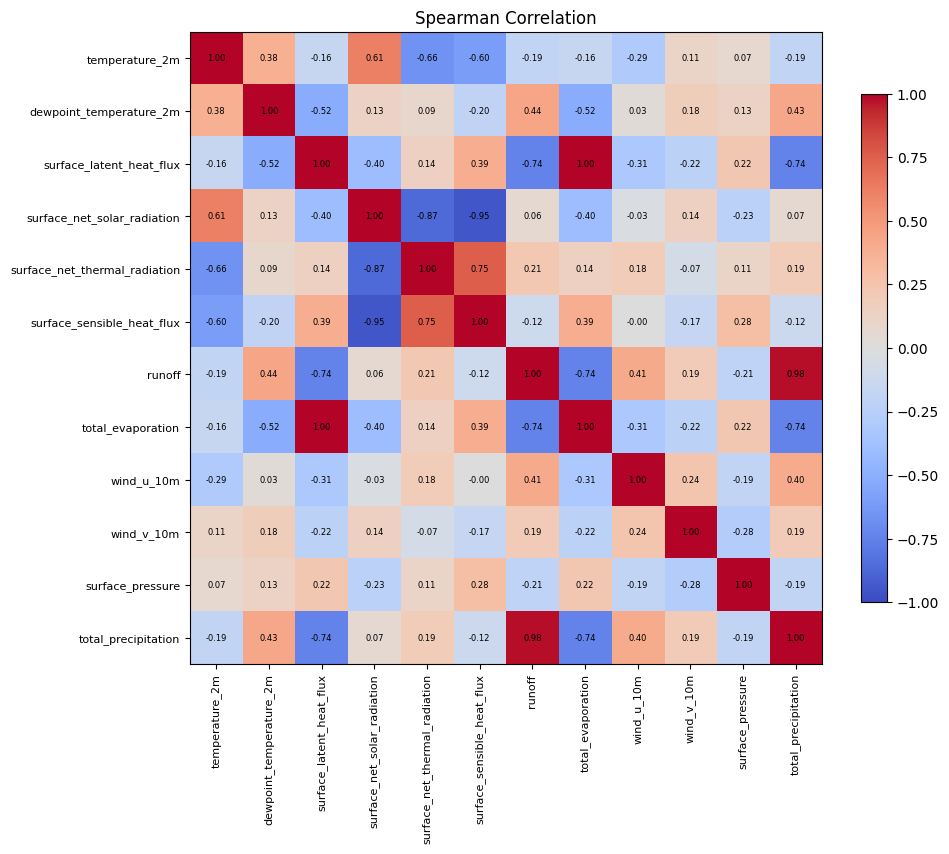

In [62]:
def heatmap(corr, title, ax):
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_yticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
    ax.set_yticklabels(corr.columns, fontsize=8)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(title)
    return im

fig, ax = plt.subplots(figsize=(10, 9))
im = heatmap(spearman, "Spearman Correlation", ax)
fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()

In [63]:
corr = spearman.where(np.triu(np.ones(spearman.shape), k=1).astype(bool)).stack().reset_index()
corr.columns = ["Feature 1", "Feature 2", "Correlation"]
display(corr[corr["Correlation"].abs() >= 0.5].sort_values("Correlation", key=abs, ascending=False).reset_index(drop=True))

,Feature 1,Feature 2,Correlation
0,surface_latent_heat_flux,total_evaporation,1.000000
1,runoff,total_precipitation,0.980426
2,surface_net_solar_radiation,surface_sensible_heat_flux,-0.948912
3,surface_net_solar_radiation,surface_net_thermal_radiation,-0.866096
4,surface_net_thermal_radiation,surface_sensible_heat_flux,0.754460
5,surface_latent_heat_flux,total_precipitation,-0.741734
6,total_evaporation,total_precipitation,-0.741732
7,surface_latent_heat_flux,runoff,-0.739611
8,runoff,total_evaporation,-0.739609
9,temperature_2m,surface_net_thermal_radiation,-0.656726


# **DATA CLEANING**
Certain values need to be resolved in this dataset before we start training the models. The final data will be called final_dataset to be used in our 2nd notebook for Step 2.

## **Data Anomaly : From 2022 to 2024**
We notice inconsistencies between 2022 and 2024 in which the average values of features like solar radiatin, thermal radiation, surface heat flux, total percipiation and total evaporation all have anomalies.

The reason of these inconsistencies is an issue affecting ERA5 accumalated featurtes within the same exact timestamp. This means instantanous features weren't affects (features like temperature). We found within the source :
- https://forum.ecmwf.int/t/issue-affecting-era5-land-monthly-averaged-reanalysis-for-the-period-september-2022-to-february-2024/2370

The data provider ERA5 didn't bother to correct their data so we instead have to do it for them.

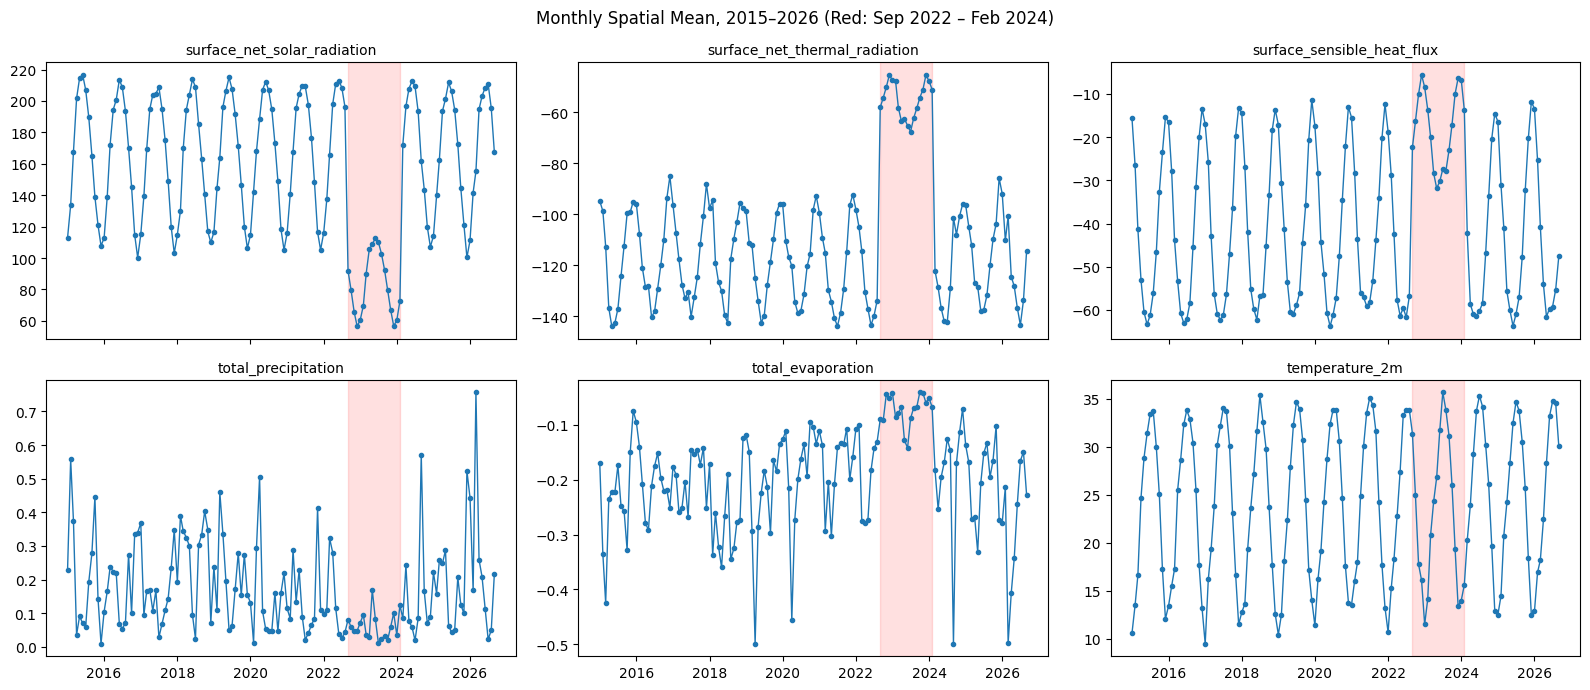

In [84]:
ACC = ["surface_latent_heat_flux", "surface_net_solar_radiation", "surface_net_thermal_radiation", "surface_sensible_heat_flux", "total_evaporation", "total_precipitation", "runoff"]
INST = ["temperature_2m", "dewpoint_temperature_2m", "wind_u_10m", "wind_v_10m", "surface_pressure"]

BAD = (dataframe["valid_time"] >= "2022-09-01") & (dataframe["valid_time"] <= "2024-02-01")

def shade(ax):
    ax.axvspan(pd.Timestamp("2022-09-01"), pd.Timestamp("2024-02-01"), color="red", alpha=0.12)

monthly = dataframe.groupby("valid_time")[ACC + INST].mean()

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for ax, v in zip(axes.ravel(), ["surface_net_solar_radiation", "surface_net_thermal_radiation", "surface_sensible_heat_flux", "total_precipitation", "total_evaporation", "temperature_2m"]):
    ax.plot(monthly.index, monthly[v], marker=".", lw=1)
    shade(ax)
    ax.set_title(v, fontsize=10)
plt.suptitle("Monthly Spatial Mean, 2015–2026 (Red: Sep 2022 – Feb 2024)")
plt.tight_layout()
plt.show()

### **Resolving the issue**
"Incorrect data from September 2022 to February 2024 will not be replaced on CDS discs nor MARS tapes. Instead users can recover the same data using the product monthly averaged reanalysis by hour of day at 00:00"

We downloaded additional data as recommended from the forum
- https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land-monthly-means?tab=download

This data contains reanalysis era5 monthly data that has the correct features we need. All we need to do is replace the features of our main dataset to said data.

### resolved data preperation :

In [91]:
# DATA PREP FOR THE RRECOVERED 2022 TO 2024 DATA
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import os
from shapely import contains_xy

raw_recovered = xr.open_dataset(os.path.join(data_path, "resolved_data_2022_2024.nc"))

# 2x2 spatial resolution reduction
data_recovered = raw_recovered.coarsen(
    latitude=2,
    longitude=2,
    boundary="trim"
).mean()

# Algeria geographical mask
algeria = gpd.read_file(os.path.join(data_path, "dz.json")).to_crs(4326)
algeria_shape = algeria.union_all()

lon2d, lat2d = np.meshgrid(
    data_recovered.longitude.values,
    data_recovered.latitude.values
)

mask = xr.DataArray(
    contains_xy(algeria_shape, lon2d, lat2d),
    coords={
        "latitude": data_recovered.latitude,
        "longitude": data_recovered.longitude
    },
    dims=["latitude", "longitude"]
)

data_recovered = data_recovered.where(mask, drop=True)

# pandas
recovered_raw = data_recovered.to_dataframe().reset_index()

recovered_raw["valid_time"] = (
    pd.to_datetime(recovered_raw["valid_time"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

recovered = pd.DataFrame({
    "valid_time": recovered_raw["valid_time"],
    "latitude": recovered_raw["latitude"],
    "longitude": recovered_raw["longitude"],
    "surface_latent_heat_flux": recovered_raw["slhf"] / 86400,
    "surface_net_solar_radiation": recovered_raw["ssr"] / 86400,
    "surface_net_thermal_radiation": recovered_raw["str"] / 86400,
    "surface_sensible_heat_flux": recovered_raw["sshf"] / 86400,
    "runoff": recovered_raw["ro"] * 1000,
    "total_evaporation": recovered_raw["e"] * 1000,
    "total_precipitation": recovered_raw["tp"] * 1000
})
recovered = recovered.dropna().reset_index(drop=True)

print("Recovered shape:", recovered.shape)
print("Period:", recovered.valid_time.min(), "until", recovered.valid_time.max())
print("Latitude:", recovered.latitude.min(), recovered.latitude.max())
print("Longitude:", recovered.longitude.min(), recovered.longitude.max())
print("Duplicates:", recovered.duplicated(
    ["latitude", "longitude", "valid_time"]
).sum())
recovered.head()

Recovered shape: (191376, 10)
Period: 2022-01-01 00:00:00 until 2024-12-01 00:00:00
Latitude: 19.049999999999873 37.05
Longitude: -8.55 11.849999999999962
Duplicates: 0


,valid_time,latitude,longitude,surface_latent_heat_flux,surface_net_solar_radiation,surface_net_thermal_radiation,surface_sensible_heat_flux,runoff,total_evaporation,total_precipitation
0,2022-01-01,37.05,6.45,-53.545509,103.978302,-65.370110,2.171751,0.076162,-1.849941,1.962410
1,2022-01-01,37.05,7.25,-64.397110,100.311874,-64.085045,22.169931,0.023562,-2.224852,2.660859
2,2022-01-01,36.85,3.85,-42.991306,106.295082,-75.308273,4.527812,0.063214,-1.485304,0.935866
3,2022-01-01,36.85,4.05,-41.767136,107.815300,-73.145294,0.263171,0.072385,-1.443010,1.024845
4,2022-01-01,36.85,4.25,-42.300594,107.512001,-72.904915,0.785201,0.071988,-1.461441,1.239587


### replacing main data 2022 to 2024 to the new resolved data

In [96]:
ACC = ["surface_latent_heat_flux", "surface_net_solar_radiation", "surface_net_thermal_radiation", "surface_sensible_heat_flux", "total_evaporation", "total_precipitation", "runoff"]
INST = ["temperature_2m", "dewpoint_temperature_2m", "wind_u_10m", "wind_v_10m", "surface_pressure"]

dataframe_corrected = dataframe.copy()

BAD = dataframe_corrected["valid_time"].between(
    "2022-09-01", "2024-02-01"
)

keys = ["valid_time", "latitude", "longitude"]

original = dataframe_corrected.loc[BAD, keys]

replacement = recovered[keys + ACC]

if replacement.duplicated(keys).any():
    raise ValueError("Duplicate rows in recovered data.")

matched = original.merge(
    replacement,
    on=keys,
    how="left",
    validate="many_to_one",
    indicator=True,
    sort=False
)

if (matched["_merge"] != "both").any():
    raise ValueError(
        f"{(matched['_merge'] != 'both').sum()} rows could not be matched."
    )

dataframe_corrected.loc[BAD, ACC] = matched[ACC].to_numpy()

print("Replacement completed!")
print("Rows replaced:", BAD.sum())
print("Final shape:", dataframe_corrected.shape)

Replacement completed!
Rows replaced: 95688
Final shape: (749556, 17)


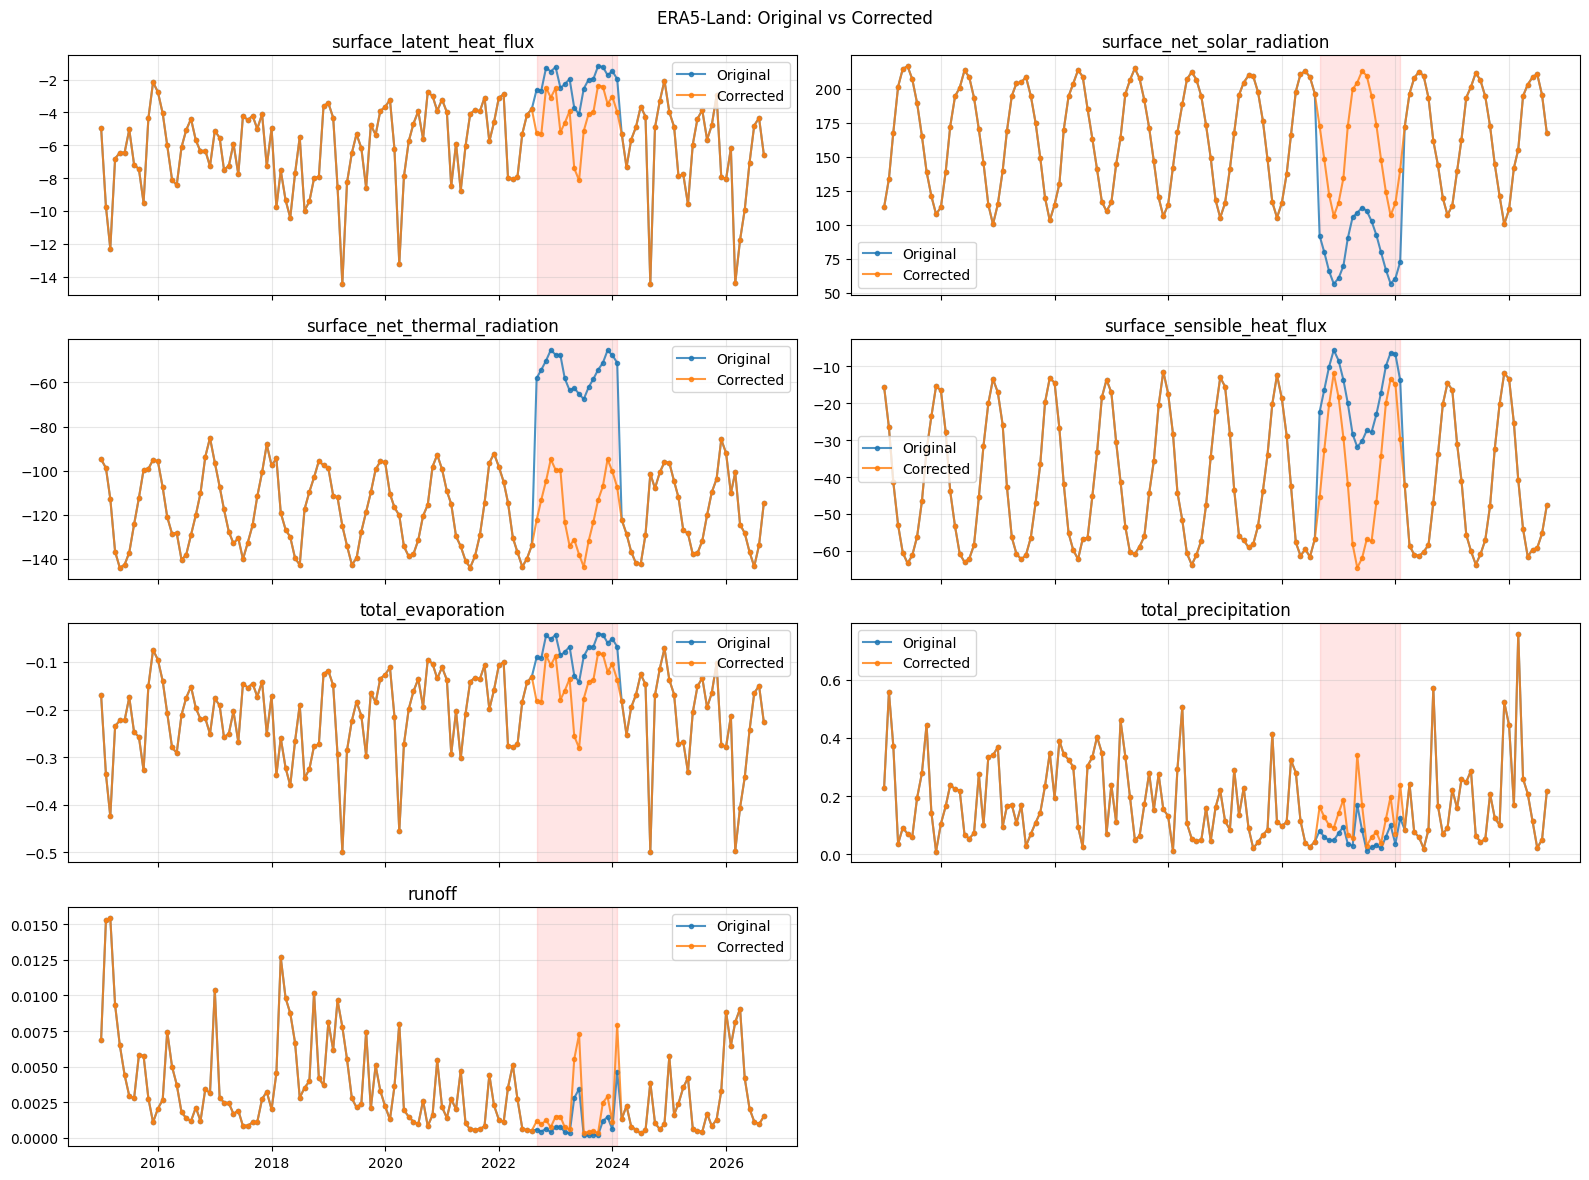

In [97]:
monthly_before = dataframe.groupby("valid_time")[ACC].mean()
monthly_after = dataframe_corrected.groupby("valid_time")[ACC].mean()

fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=True)

for ax, col in zip(axes.ravel(), ACC):
    ax.plot(monthly_before.index, monthly_before[col],
            label="Original", alpha=0.8, marker=".")
    ax.plot(monthly_after.index, monthly_after[col],
            label="Corrected", alpha=0.8, marker=".")

    ax.axvspan(pd.Timestamp("2022-09-01"),
               pd.Timestamp("2024-02-01"),
               color="red", alpha=0.10)

    ax.set_title(col)
    ax.legend()
    ax.grid(alpha=0.3)

axes.ravel()[-1].remove()

plt.suptitle("ERA5-Land: Original vs Corrected")
plt.tight_layout()
plt.show()

## **Dealing with skewed data :**
From the EDA histogram we found skewed data such as precipitation, runoff, total evaporation. We can deal with them using the log transformation.

In [98]:
SKEWED = ["total_precipitation", "runoff", "total_evaporation"]

# Convert evaporation to positive values
dataframe_corrected["total_evaporation"] *= -1

before = dataframe_corrected[SKEWED].copy()

def iqr_outlier_share(data, columns):
    Q1 = data[columns].quantile(0.25)
    Q3 = data[columns].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[columns].lt(lower) | data[columns].gt(upper)
    return outliers.mean() * 100

dataframe_corrected[SKEWED] = np.log(dataframe_corrected[SKEWED] + 0.01)

display(pd.DataFrame({
    "Skew before": before.skew(),
    "Skew after": dataframe_corrected[SKEWED].skew(),
    "Outliers before (%)": iqr_outlier_share(before, SKEWED),
    "Outliers after (%)": iqr_outlier_share(dataframe_corrected, SKEWED)
}))

,Skew before,Skew after,Outliers before (%),Outliers after (%)
total_precipitation,5.616599,0.981715,15.080794,0.548191
runoff,29.465851,6.257676,16.215333,15.991867
total_evaporation,4.119388,1.112828,16.748582,8.414982


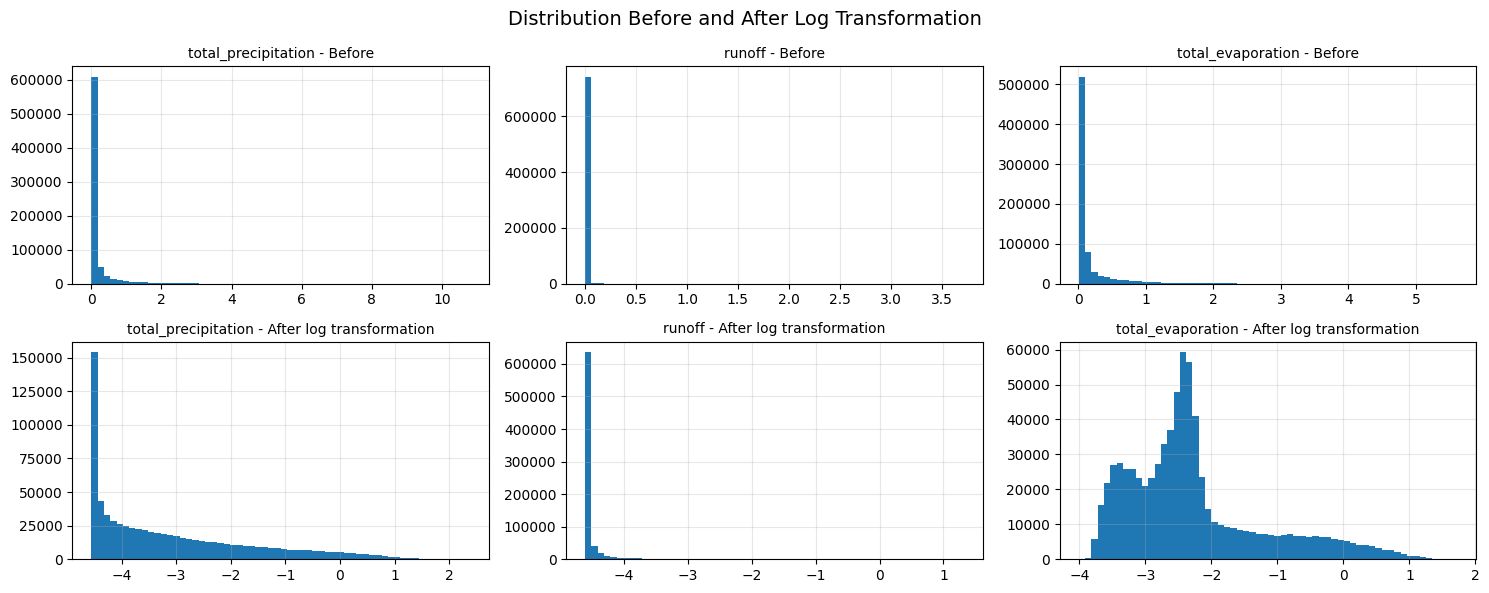

In [102]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))

for j, v in enumerate(SKEWED):
    axes[0, j].hist(before[v], bins=60)
    axes[0, j].set_title(f"{v} - Before", fontsize=10)
    axes[0, j].grid(alpha=0.3)

    axes[1, j].hist(dataframe_corrected[v], bins=60)
    axes[1, j].set_title(f"{v} - After log transformation", fontsize=10)
    axes[1, j].grid(alpha=0.3)

fig.suptitle("Distribution Before and After Log Transformation", fontsize=14)
plt.tight_layout()
plt.show()

### The issue with runoff
We can notice that runoff stays skewed since it's values are very close to zero. We also know that from the correlation matrix :
- runoff	total_precipitation	0.980426

That means they have a very close correlation. We can remove it or keep it, for now we will keep it as it might provide additional info and isn't 100% equivalent to percipitation.

### **Removing Redundant Features**
Surface latent heatflux and Runoff both are redundant in a way. For now surface latent heatflux is the only feature to be removed, as it has an equivalent correlation with evaporation.

In [104]:
dataframe_corrected = dataframe_corrected.drop(
    columns=["surface_latent_heat_flux"]
)
dataframe_corrected.head()

,valid_time,latitude,longitude,year,month,temperature_2m,dewpoint_temperature_2m,surface_net_solar_radiation,surface_net_thermal_radiation,surface_sensible_heat_flux,runoff,total_evaporation,wind_u_10m,wind_v_10m,surface_pressure,total_precipitation
0,2015-01-01,37.05,6.45,2015,1,9.939758,6.176270,92.773232,-56.551544,8.933703,-0.823110,0.680732,2.933837,-0.261126,982.692139,1.673082
1,2015-01-01,37.05,7.25,2015,1,12.124664,7.952301,94.120605,-61.004883,42.022015,-1.478294,1.020717,3.638752,-0.917213,1014.828735,1.800262
2,2015-01-01,36.85,3.85,2015,1,10.367828,5.971832,86.805702,-60.176083,19.700659,-0.947827,0.610220,2.284870,0.571068,999.108765,1.613317
3,2015-01-01,36.85,4.05,2015,1,9.523590,5.382965,87.194870,-57.047768,12.613502,-0.326438,0.525976,2.284626,0.510155,982.861267,1.720918
4,2015-01-01,36.85,4.25,2015,1,9.327148,5.355286,86.925423,-56.865517,12.040462,-0.230509,0.510756,2.298257,0.530866,981.838745,1.783139
